# EOS Consistency Check

## Setup

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import numpy as np
import matplotlib.pyplot as pl
import scipy
import scipy.io
import scipy.interpolate
import sys
import os

In [4]:
top='c:/cygwin64/home/codes/dispatch2/'
sys.path.insert(0,top+'utilities/python')
cwd=top+'data/eos/Tomida+Hori_2016'
os.chdir(cwd)

In [5]:
import dispatch

## Read EOS data

In [95]:
import dispatch.EOS
eos=dispatch.EOS.Tomida_Hori_2016(verbose=2)

dir: ../../../data/eos/Tomida+Hori_2016/
reading data from tomida.dat
vars: ['ln(P)', 'ln(E)', 'ln(C_T)', 'ln(cs)', 'gamma', 'ln(Cv)']


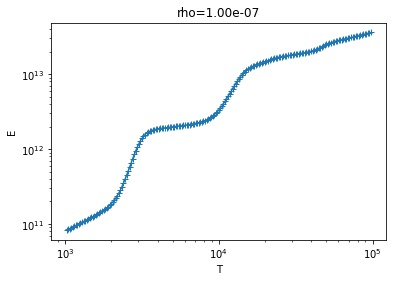

In [99]:
j=300
lnT,lnP=eos.values(j,0)
lnT,lnE=eos.values(j,1)
T=np.exp(lnT)
E=np.exp(lnE)
w=np.where(abs(lnT/np.log(10)-4)<1)[0]
pl.loglog(T[w],E[w],'-+')
pl.title('rho={:.2e}'.format(d))
pl.xlabel('T'); pl.ylabel('E');

## Difference in cross-derivatives

Text(0.5, 0, 'T')

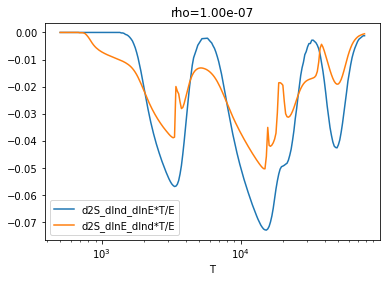

In [83]:
from dispatch.EOS import deriv,interp

def d2S_dlnE_dlnd(j0):
    def dS_dlnE(j):
        lnT,lnP=eos.values(j,0)
        lnT,lnE=eos.values(j,1)
        T=np.exp(lnT)
        E=np.exp(lnE)
        return E/T,E,T
    j1=j0+1
    dS_dlnE_0,E0,T0=dS_dlnE(j0)        # dS_dlnE on E0 scale
    dS_dlnE_1,E1,T1=dS_dlnE(j1)        # dS_dlnE on E1 scale
    dS_dlnE_1=interp(E1,dS_dlnE_1,E0)  # dS_dlnE on E0 scale
    T1=interp(E1,T1,E0)                # T1 on E0 scale
    lnd_step=eos.scale0.step
    return (dS_dlnE_1-dS_dlnE_0)/lnd_step*(T0+T1)/(E0+E0),T1

def d2S_dlnd_dlnE(j):
    """ \partial S^2 \over \partial\ln\rho \partial\ln E """
    def d2S(j):
        d=np.exp(eos.scale0.values[j])
        lnT,lnP=eos.values(j,0)
        lnT,lnE=eos.values(j,1)
        T=np.exp(lnT)
        P=np.exp(lnP)
        E=np.exp(lnE)
        dS_dlnd=-P/(d*T)
        return deriv(lnE,dS_dlnd),E,T,lnE
    d2S0,E0,T0,lnE0=d2S(j0)
    d2S1,E1,T1,lnE1=d2S(j1)
    d2S1=interp(E1,d2S1,E0)
    T1=interp(E1,T1,E0)
    return (d2S0+d2S1)/2*(T0+T1)/(E0+E0),T1
j0=300
d2S_1,T1=d2S_dlnE_dlnd(j0)
d2S_2,T2=d2S_dlnd_dlnE(j0)
w=np.arange(230,450)
pl.semilogx(T1[w],d2S_1[w],label='d2S_dlnd_dlnE*T/E')
pl.semilogx(T1[w],d2S_2[w],label='d2S_dlnE_dlnd*T/E')
d=np.exp(eos.scale0.values[j0])
pl.legend(); pl.title('rho={:.2e}'.format(d)); pl.xlabel('T')